In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_raw = pd.read_csv('../data/data.csv', encoding='ISO-8859-1')

print(df_raw.info())
df_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
None


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10,6]

In [4]:
df_clean = df_raw.dropna(subset=['CustomerID']).copy()
df_clean['CustomerId'] = df_clean['CustomerID'].astype(int)

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

df_clean = df_clean[df_clean['UnitPrice'] > 0]

service_codes = ['POST', 'D', 'M', 'DOT', 'BANK CHARGES', 'CRUK']
df_clean = df_clean[~df_clean['StockCode'].isin(service_codes)]

df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Строк после очистки ; {df_clean.shape[0]}")

Строк после очистки ; 405013


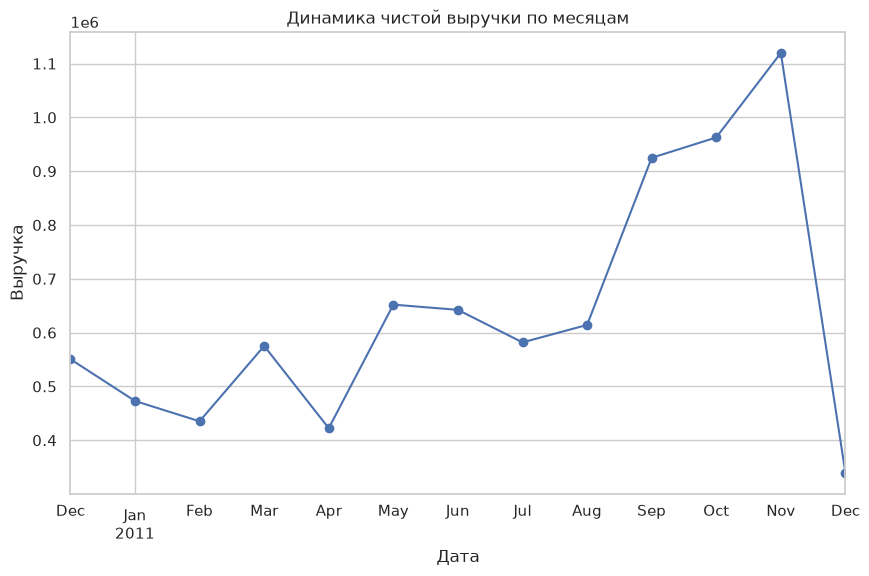

In [5]:
monthly_sales = df_clean.set_index('InvoiceDate').resample('ME')['TotalAmount'].sum()

monthly_sales.plot(kind='line', marker='o', color='b')
plt.title('Динамика чистой выручки по месяцам')
plt.xlabel('Дата')
plt.ylabel('Выручка')
plt.show()

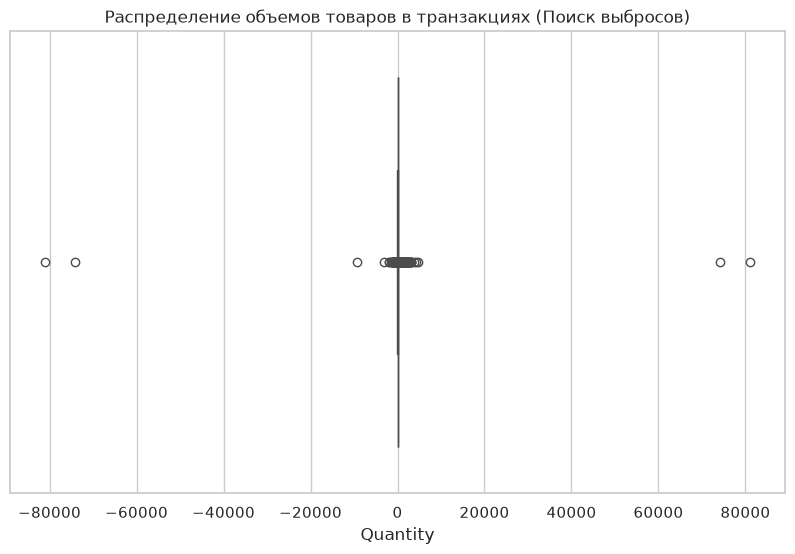

In [6]:
sns.boxplot(x=df_clean['Quantity'])

plt.title('Распределение объемов товаров в транзакциях (Поиск выбросов)')
plt.show()


In [7]:
today_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
  #Прописать Recency, Frequency, Monetary 
    # Recency: из сегодняшней даты вычитаем дату последней покупки и берем чистые дни
    'InvoiceDate': lambda x: (today_date - x.max()).days,
    # Frequency: считаем количество УНИКАЛЬНЫХ инвойсов (чеков)
    'InvoiceNo': 'nunique',
    # Monetary: складываем суммы всех позиций (возвраты вычтутся сами)
    'TotalAmount': 'sum' 
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm = rfm[rfm['Monetary'] > 0]

print(f"Итого уникальных клиентов в витрине : {rfm.shape[0]}")
rfm.head()

Итого уникальных клиентов в витрине : 4325


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,2,7,4310.00
12348.0,75,4,1437.24
12349.0,19,1,1457.55
12350.0,310,1,294.40
12352.0,36,8,1265.41


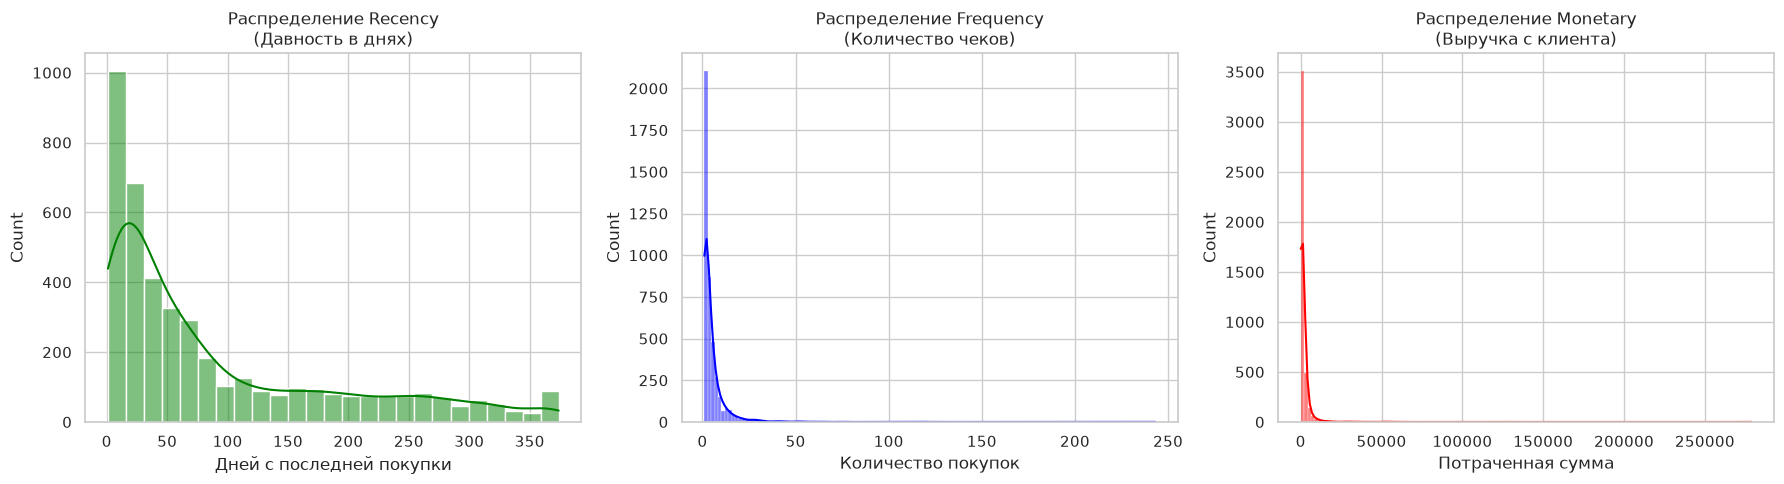

In [8]:
#анализ распределения метрик 
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Создаем сетку из 3 графиков в один ряд
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Распределение Recency (Давность)
sns.histplot(rfm['Recency'], kde=True, ax=axes[0], color='green')
axes[0].set_title('Распределение Recency\n(Давность в днях)')
axes[0].set_xlabel('Дней с последней покупки')

# График 2: Распределение Frequency (Частота)
sns.histplot(rfm['Frequency'], kde=True, ax=axes[1], color='blue')
axes[1].set_title('Распределение Frequency\n(Количество чеков)')
axes[1].set_xlabel('Количество покупок')

# График 3: Распределение Monetary (Деньги)
sns.histplot(rfm['Monetary'], kde=True, ax=axes[2], color='red')
axes[2].set_title('Распределение Monetary\n(Выручка с клиента)')
axes[2].set_xlabel('Потраченная сумма')

plt.tight_layout()
plt.show()



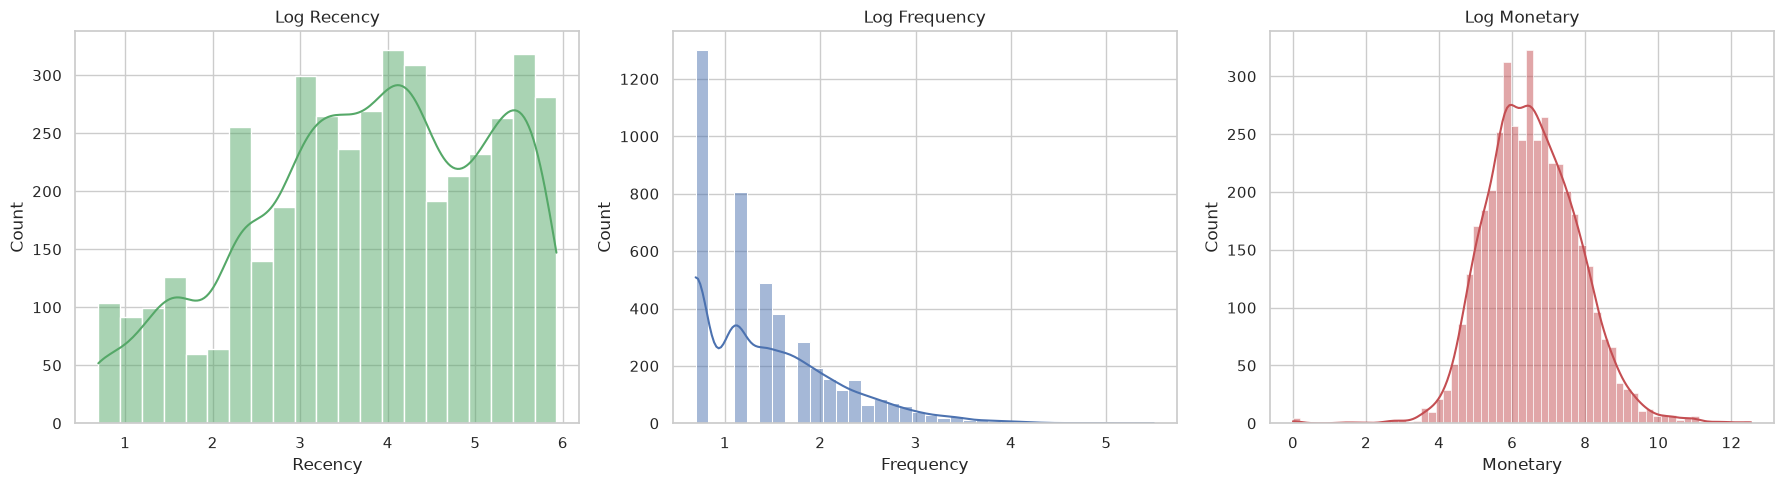

In [ ]:
import numpy as np

rfm_log = np.log1p(rfm)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(rfm_log['Recency'], kde=True, ax=axes[0], color='g').set_title('Log Recency')
sns.histplot(rfm_log['Frequency'], kde=True, ax=axes[1], color='b').set_title('Log Frequency')
sns.histplot(rfm_log['Monetary'], kde=True, ax=axes[2], color='r').set_title('Log Monetary')
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(rfm_scaled, index=rfm.index, columns=rfm.columns)
rfm_scaled.head()


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,-1.972634,0.873055,1.432690
12348.0,0.398706,0.231584,0.566255
12349.0,-0.580757,-1.018989,0.577323
12350.0,1.432504,-1.018989,-0.683056
12352.0,-0.129408,1.033808,0.465832


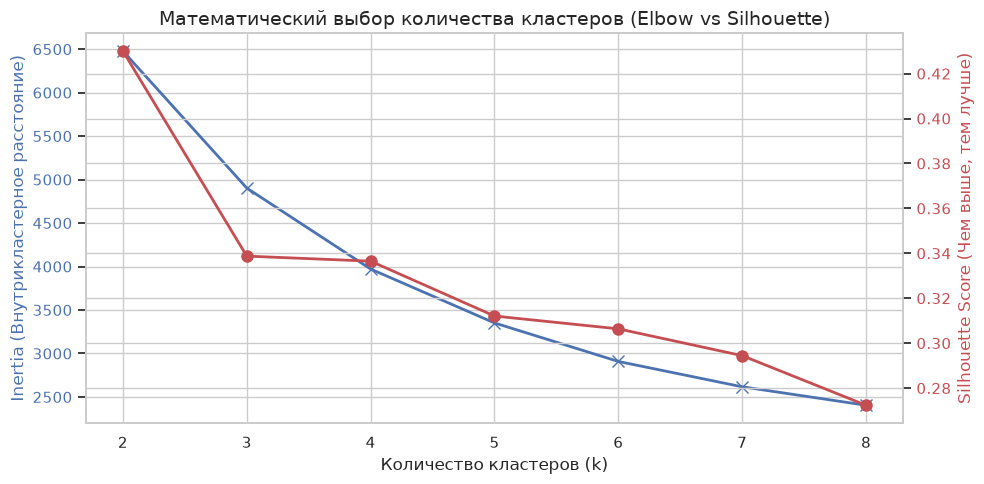

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_vals = []
K_range = range(2, 9) # Проверяем от 2 до 8 кластеров

for k in K_range:
    # random_state=42 фиксирует генератор случайных чисел, чтобы результат всегда был одинаковым
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    
   
    inertia.append(kmeans.inertia_) 
    
    
    silhouette_vals.append(silhouette_score(rfm_scaled, kmeans.labels_))

fig, ax1 = plt.subplots(figsize=(10, 5))


ax1.plot(K_range, inertia, 'bx-', linewidth=2, markersize=8)
ax1.set_xlabel('Количество кластеров (k)', fontsize=12)
ax1.set_ylabel('Inertia (Внутрикластерное расстояние)', color='b', fontsize=12)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)


ax2 = ax1.twinx()

ax2.plot(K_range, silhouette_vals, 'ro-', linewidth=2, markersize=8)
ax2.set_ylabel('Silhouette Score (Чем выше, тем лучше)', color='r', fontsize=12)
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Математический выбор количества кластеров (Elbow vs Silhouette)', fontsize=14)
fig.tight_layout()
plt.show()


In [ ]:
from sklearn.cluster import KMeans

# 1. Инициализируем модель на 4 кластера
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# 2. Обучаем на масштабированных данных
final_kmeans.fit(rfm_scaled)

# 3. Добавляем метки кластеров (0, 1, 2, 3) в нашу ИСХОДНУЮ таблицу с реальными значениями
rfm['Cluster'] = final_kmeans.labels_

# Сколько клиентов попало в каждый кластер
print(rfm['Cluster'].value_counts().sort_index())
rfm.head()


Cluster
0     854
1    1638
2    1121
3     712
Name: count, dtype: int64


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12347.0,2,7,4310.00,3
12348.0,75,4,1437.24,2
12349.0,19,1,1457.55,0
12350.0,310,1,294.40,1
12352.0,36,8,1265.41,2


In [13]:
# Группируем по кластерам и считаем среднее (и количество клиентов)
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'Client_Count'}).round(1)

# Выводим профиль на экран
cluster_profile


,Recency,Frequency,Monetary,Client_Count
Cluster,,,,
0,16.6,2.5,585.1,854
1,177.2,1.5,334.5,1638
2,71.3,4.9,1676.3,1121
3,11.0,16.4,7543.1,712


1. Кластер с минимальным Recency, максимальным Frequency и огромным Monetary:
	• Кто это: Это «Чемпионы» (VIP-клиенты). Они покупали совсем недавно, покупают постоянно и приносят львиную долю выручки.

2. Кластер с большим Recency, маленьким Frequency и маленьким Monetary:
	• Кто это: «Уснувшие» / «Ушедшие». Они купили один-два раза очень давно и больше не возвращались.

3. Кластер с маленьким Recency, но небольшим Frequency и Monetary:
	• Кто это: «Новички». Заходили недавно, сделали первый пробный заказ. Их нужно аккуратно прогревать рекламой.

4. Кластер со средним Recency, высокой частотой и хорошими деньгами:
	• Кто это: «В зоне риска». Лояльные клиенты, которые раньше покупали часто, но в последнее время начали пропадать. Маркетологам нужно срочно слать им промокод на скидку, пока они не ушли совсем.

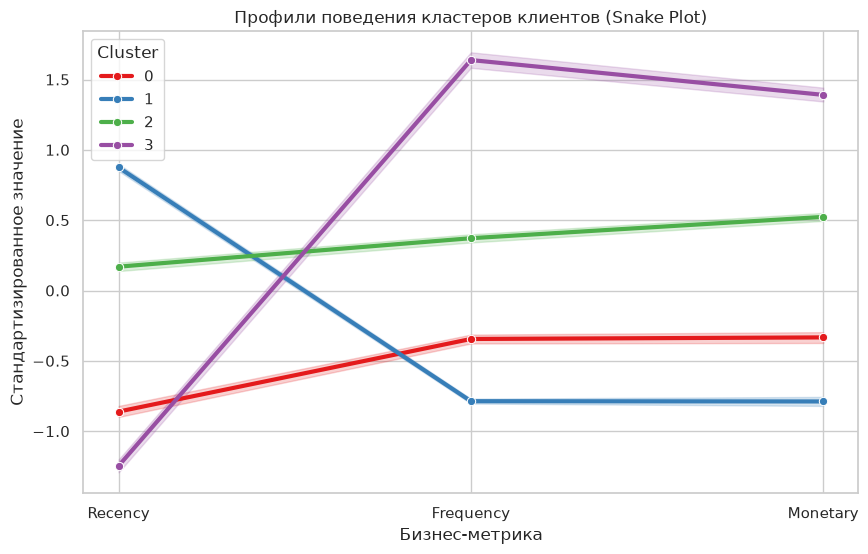

In [ ]:

rfm_scaled_copy = rfm_scaled.copy()
rfm_scaled_copy['Cluster'] = final_kmeans.labels_

df_melt = pd.melt(rfm_scaled_copy.reset_index(), 
                  id_vars=['CustomerID', 'Cluster'],
                  value_vars=['Recency', 'Frequency', 'Monetary'],
                  var_name='Metric', 
                  value_name='Value')

# Строим линейный график по кластерам
plt.figure(figsize=(10, 6))
sns.lineplot(x='Metric', y='Value', hue='Cluster', data=df_melt, palette='Set1', marker='o', linewidth=3)
plt.title('Профили поведения кластеров клиентов (Snake Plot)')
plt.ylabel('Стандартизированное значение')
plt.xlabel('Бизнес-метрика')
plt.show()
